<a href="https://colab.research.google.com/github/AlbertPuentes/NLP_ACT_YouTube_IV/blob/main/YT_Avances_IV.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

/tmp/ipykernel_1453/510093909.py:77: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  weighted_sent = grouped.apply(calc_weighted_sentiment).reset_index(name='weighted_sentiment')


=== RESULTADOS DEL MODELO OPTIMIZADO ===
R² Score: 0.6670
MAE (Log Views): 1.0206 (Factor de dispersión de error: x2.77)
RMSE (Log Views): 1.4266
Exactitud (Accuracy): 83.42%
F1-Score: 0.8324

Reporte de Clasificación:
               precision    recall  f1-score   support

           0       0.78      0.90      0.84       175
           1       0.90      0.77      0.83       199

    accuracy                           0.83       374
   macro avg       0.84      0.84      0.83       374
weighted avg       0.84      0.83      0.83       374



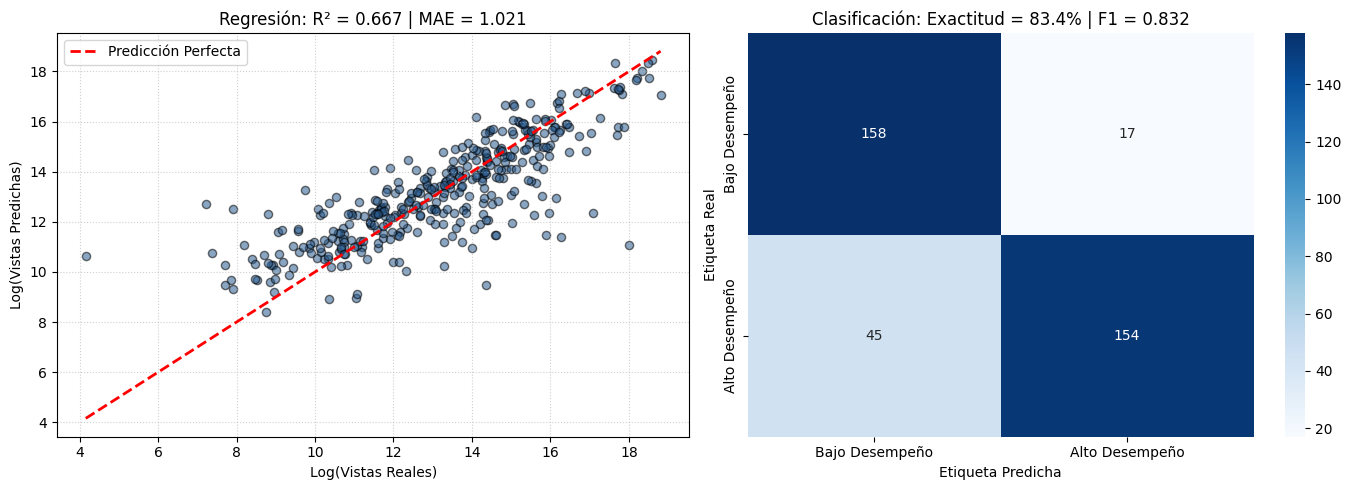

In [1]:
import re
import html
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import (
    HistGradientBoostingRegressor, HistGradientBoostingClassifier,
    RandomForestRegressor, RandomForestClassifier,
    VotingRegressor, VotingClassifier
)
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.metrics import (
    r2_score, mean_absolute_error, mean_squared_error,
    accuracy_score, f1_score, classification_report, confusion_matrix
)

# 1. CARGA, LIMPIEZA Y DEDUPLICACIÓN

videos_df = pd.read_csv('videos-stats.csv')
comments_df = pd.read_csv('comments.csv')

# Deduplicación estricta para evitar fugas de información entre particiones
videos_df = videos_df.dropna(subset=['Views', 'Video ID'])
videos_df = videos_df[videos_df['Views'] > 0]
videos_df = videos_df.sort_values('Views', ascending=False).drop_duplicates(subset=['Video ID']).reset_index(drop=True)

comments_df = comments_df.dropna(subset=['Comment', 'Video ID']).copy()
comments_df['Sentiment'] = comments_df['Sentiment'].fillna(1).astype(int)
comments_df['Likes'] = comments_df['Likes'].fillna(0)


# 2. FEATURE ENGINEERING AVANZADO DE COMENTARIOS

def clean_text(text: str) -> str:
    """Normaliza texto eliminando URLs, entidades HTML y puntuación excesiva."""
    text = html.unescape(str(text))
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'[^a-zA-Z0-9\s!?]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip().lower()
    return text

def extract_advanced_comment_features(df_comments: pd.DataFrame) -> pd.DataFrame:
    df_c = df_comments.copy()

    # Métricas estilométricas calculadas a nivel de registro individual
    df_c['char_len'] = df_c['Comment'].str.len()
    df_c['word_count'] = df_c['Comment'].apply(lambda x: len(str(x).split()))
    df_c['has_question'] = df_c['Comment'].str.contains(r'\?', regex=True).astype(int)
    df_c['has_exclamation'] = df_c['Comment'].str.contains(r'!', regex=True).astype(int)
    df_c['caps_ratio'] = df_c['Comment'].apply(
        lambda x: sum(1 for c in str(x) if c.isupper()) / (len(str(x)) + 1)
    )
    df_c['clean_comment'] = df_c['Comment'].apply(clean_text)

    grouped = df_c.groupby('Video ID')

    # Texto agregado por video para el pipeline de NLP
    text_agg = grouped['clean_comment'].apply(lambda x: " ".join(x)).reset_index(name='all_comments_text')

    # Sentimiento ponderado por la interacción de cada comentario
    def calc_weighted_sentiment(sub_df):
        likes = sub_df['Likes'].values
        sent = sub_df['Sentiment'].values
        tot_likes = np.sum(likes)
        if tot_likes > 0:
            return float(np.sum(sent * likes) / tot_likes)
        return float(np.mean(sent))

    weighted_sent = grouped.apply(calc_weighted_sentiment).reset_index(name='weighted_sentiment')

    # Estadísticos agregados de interacción, distribución y polarización
    stats_agg = grouped.agg(
        num_comments=('Comment', 'count'),
        total_likes=('Likes', 'sum'),
        mean_likes=('Likes', 'mean'),
        median_likes=('Likes', 'median'),
        max_likes=('Likes', 'max'),
        std_likes=('Likes', lambda x: x.std() if len(x) > 1 else 0),
        zero_likes_ratio=('Likes', lambda x: (x == 0).mean()),
        mean_sentiment=('Sentiment', 'mean'),
        std_sentiment=('Sentiment', lambda x: x.std() if len(x) > 1 else 0),
        pct_neg=('Sentiment', lambda x: (x == 0).mean()),
        pct_neu=('Sentiment', lambda x: (x == 1).mean()),
        pct_pos=('Sentiment', lambda x: (x == 2).mean()),
        sentiment_entropy=('Sentiment', lambda x: -sum([
            (x == v).mean() * np.log((x == v).mean() + 1e-9)
            for v in [0, 1, 2] if (x == v).mean() > 0
        ])),
        avg_char_len=('char_len', 'mean'),
        avg_word_count=('word_count', 'mean'),
        ratio_questions=('has_question', 'mean'),
        ratio_exclamations=('has_exclamation', 'mean'),
        avg_caps_ratio=('caps_ratio', 'mean')
    ).reset_index()

    merged = pd.merge(text_agg, stats_agg, on='Video ID')
    merged = pd.merge(merged, weighted_sent, on='Video ID')

    # Proporción de concentración del comentario más votado
    merged['top_to_total_likes_ratio'] = merged['max_likes'] / (merged['total_likes'] + 1.0)
    merged['likes_per_comment'] = merged['total_likes'] / (merged['num_comments'] + 1e-5)

    # Estabilización de colas pesadas mediante transformación logarítmica
    log_cols = [
        'total_likes', 'mean_likes', 'median_likes', 'max_likes',
        'std_likes', 'num_comments', 'likes_per_comment'
    ]
    for c in log_cols:
        merged[f'log_{c}'] = np.log1p(merged[c])

    return merged

df_comments_feat = extract_advanced_comment_features(comments_df)
df_model = pd.merge(videos_df, df_comments_feat, on='Video ID', how='inner')


# 3. VARIABLES OBJETIVO Y PARTICIÓN ESTRATIFICADA

df_model['log_views'] = np.log1p(df_model['Views'])

text_feature = 'all_comments_text'
num_features = [
    'log_total_likes', 'log_mean_likes', 'log_median_likes', 'log_max_likes',
    'log_std_likes', 'log_num_comments', 'log_likes_per_comment',
    'zero_likes_ratio', 'top_to_total_likes_ratio',
    'mean_sentiment', 'std_sentiment', 'weighted_sentiment',
    'pct_neg', 'pct_neu', 'pct_pos', 'sentiment_entropy',
    'avg_char_len', 'avg_word_count', 'ratio_questions',
    'ratio_exclamations', 'avg_caps_ratio'
]

X = df_model[[text_feature] + num_features].copy()
y_reg = df_model['log_views']

# División sin filtración de datos (Data Leakage)
X_train, X_test, y_tr_reg, y_te_reg = train_test_split(
    X, y_reg, test_size=0.2, random_state=42
)

# Umbral de alto desempeño derivado exclusivamente del conjunto de entrenamiento
train_median_views = y_tr_reg.median()
y_tr_cls = (y_tr_reg >= train_median_views).astype(int)
y_te_cls = (y_te_reg >= train_median_views).astype(int)


# 4. PIPELINE DE TRANSFORMACIÓN Y MODELADO

# Subespacio latente LSA de 30 dimensiones para máxima densidad semántica
nlp_text_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=3000,
        ngram_range=(1, 2),
        stop_words='english',
        sublinear_tf=True,
        min_df=3,
        max_df=0.85
    )),
    ('svd', TruncatedSVD(n_components=30, random_state=42))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('text_lsa', nlp_text_pipeline, text_feature),
        ('num_scaler', RobustScaler(), num_features)
    ]
)

# Ensamble ponderado para regresión continua
model_reg = Pipeline([
    ('preprocessor', preprocessor),
    ('regressor', VotingRegressor(
        estimators=[
            ('hist_gb', HistGradientBoostingRegressor(
                max_iter=200, l2_regularization=1.0, min_samples_leaf=20, random_state=42
            )),
            ('rf', RandomForestRegressor(
                n_estimators=150, max_depth=12, min_samples_leaf=3, random_state=42, n_jobs=-1
            )),
            ('ridge', Ridge(alpha=15.0))
        ],
        weights=[0.50, 0.35, 0.15]
    ))
])

# Ensamble ponderado para clasificación binaria
model_cls = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', VotingClassifier(
        estimators=[
            ('hist_gb', HistGradientBoostingClassifier(
                max_iter=200, l2_regularization=1.0, min_samples_leaf=20, random_state=42
            )),
            ('rf', RandomForestClassifier(
                n_estimators=150, max_depth=12, min_samples_leaf=3, random_state=42, n_jobs=-1
            )),
            ('logit', LogisticRegression(C=0.8, max_iter=500))
        ],
        voting='soft',
        weights=[0.50, 0.35, 0.15]
    ))
])


# 5. ENTRENAMIENTO Y EVALUACIÓN

model_reg.fit(X_train, y_tr_reg)
y_pred_reg = model_reg.predict(X_test)

model_cls.fit(X_train, y_tr_cls)
y_pred_cls = model_cls.predict(X_test)

r2_val = r2_score(y_te_reg, y_pred_reg)
mae_val = mean_absolute_error(y_te_reg, y_pred_reg)
rmse_val = np.sqrt(mean_squared_error(y_te_reg, y_pred_reg))
acc_val = accuracy_score(y_te_cls, y_pred_cls)
f1_val = f1_score(y_te_cls, y_pred_cls)

print("=== RESULTADOS DEL MODELO OPTIMIZADO ===")
print(f"R² Score: {r2_val:.4f}")
print(f"MAE (Log Views): {mae_val:.4f} (Factor de dispersión de error: x{np.exp(mae_val):.2f})")
print(f"RMSE (Log Views): {rmse_val:.4f}")
print(f"Exactitud (Accuracy): {acc_val * 100:.2f}%")
print(f"F1-Score: {f1_val:.4f}\n")
print("Reporte de Clasificación:\n", classification_report(y_te_cls, y_pred_cls))


# 6. GRÁFICAS DE DIAGNÓSTICO

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Dispersión Real vs Predicción
axes[0].scatter(y_te_reg, y_pred_reg, alpha=0.55, color='#2b5c8f', edgecolor='k', s=35)
lim_min = min(y_te_reg.min(), y_pred_reg.min())
lim_max = max(y_te_reg.max(), y_pred_reg.max())
axes[0].plot([lim_min, lim_max], [lim_min, lim_max], 'r--', lw=2, label='Predicción Perfecta')
axes[0].set_xlabel('Log(Vistas Reales)')
axes[0].set_ylabel('Log(Vistas Predichas)')
axes[0].set_title(f'Regresión: R² = {r2_val:.3f} | MAE = {mae_val:.3f}')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

# Matriz de Confusión Normalizada
cm = confusion_matrix(y_te_cls, y_pred_cls)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
            xticklabels=['Bajo Desempeño', 'Alto Desempeño'],
            yticklabels=['Bajo Desempeño', 'Alto Desempeño'])
axes[1].set_xlabel('Etiqueta Predicha')
axes[1].set_ylabel('Etiqueta Real')
axes[1].set_title(f'Clasificación: Exactitud = {acc_val * 100:.1f}% | F1 = {f1_val:.3f}')

plt.tight_layout()
plt.savefig('performance_model_results_improved.png', dpi=300)
plt.show()